In [3]:
!git clone https://github.com/RonnieKeene/flying_through_chaos_a26/

Cloning into 'flying_through_chaos_a26'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 49 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 3.82 MiB | 5.08 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data exported from Week 5.
regression_df = pd.read_csv(
    "/content/flying_through_chaos_a26/regression_data.csv",
    parse_dates=["hour_local"]
)

# All remaining columns are predictors.
core_features = regression_df.columns.drop(
    ["hour_local", "avg_departure_delay"]
).tolist()

print(f"Loaded {len(regression_df):,} rows and {len(core_features)} predictors.")

Loaded 28,499 rows and 23 predictors.


In [29]:
regression_df.head()

,hour_local,scheduled_flights,airlines,origins,avg_distance,avg_scheduled_flight_time,temperature_c,wind_max_ms,visibility_min_m,dew_point_spread_c,...,hour_cos,season_sin,season_cos,dow_tue,dow_wed,dow_thu,dow_fri,dow_sat,dow_sun,avg_departure_delay
0,2022-01-01 00:00:00,8,4,8,1249.625000,191.750000,3.333333,9.3,3219.0,1.833333,...,1.000000e+00,0.0,1.0,0,0,0,0,1,0,183.800000
1,2022-01-01 05:00:00,13,4,8,1680.000000,231.153846,1.100000,6.7,11265.0,2.200000,...,2.588190e-01,0.0,1.0,0,0,0,0,1,0,42.625000
2,2022-01-01 06:00:00,7,3,5,2800.285714,346.571429,1.500000,11.3,11000.0,2.266667,...,6.123234e-17,0.0,1.0,0,0,0,0,1,0,43.000000
3,2022-01-01 07:00:00,27,7,24,536.148148,129.148148,0.850000,10.3,9656.0,2.250000,...,-2.588190e-01,0.0,1.0,0,0,0,0,1,0,17.380952
4,2022-01-01 08:00:00,33,8,32,551.575758,128.666667,0.200000,7.7,4828.0,1.900000,...,-5.000000e-01,0.0,1.0,0,0,0,0,1,0,14.153846


In [30]:
regression_df.tail()

,hour_local,scheduled_flights,airlines,origins,avg_distance,avg_scheduled_flight_time,temperature_c,wind_max_ms,visibility_min_m,dew_point_spread_c,...,hour_cos,season_sin,season_cos,dow_tue,dow_wed,dow_thu,dow_fri,dow_sat,dow_sun,avg_departure_delay
28494,2025-08-24 23:00:00,23,7,18,1114.826087,188.173913,16.1,3.1,16093.0,7.2,...,9.659258e-01,-0.785650,-0.618671,0,0,0,0,0,1,34.565217
28495,2025-08-25 00:00:00,6,3,5,1324.833333,206.000000,15.6,4.1,16093.0,6.2,...,1.000000e+00,-0.796183,-0.605056,0,0,0,0,0,0,211.833333
28496,2025-08-25 04:00:00,3,3,2,1653.333333,238.666667,12.8,3.6,16093.0,3.4,...,5.000000e-01,-0.796183,-0.605056,0,0,0,0,0,0,-0.333333
28497,2025-08-25 05:00:00,10,4,7,1787.600000,250.600000,12.8,4.1,16093.0,3.4,...,2.588190e-01,-0.796183,-0.605056,0,0,0,0,0,0,-1.000000
28498,2025-08-25 06:00:00,32,5,28,636.250000,127.562500,12.8,4.1,16093.0,3.4,...,6.123234e-17,-0.796183,-0.605056,0,0,0,0,0,0,1.031250


In [7]:
# Sort our data by date and time
data = regression_df.sort_values("hour_local")

# X contains the features we use to make predictions
X = data[core_features]

# y contains the variable we want to predict
y = data["avg_departure_delay"]

In [8]:
# Sort data chronologically
data = regression_df.sort_values("hour_local")

X = data[core_features]
y = data["avg_departure_delay"]

In [12]:
from sklearn.model_selection import train_test_split

train_index = int(len(X) * .70)
val_index = int(len(X) * .85)

X_train = X.iloc[0:train_index]
y_train = y.iloc[0:train_index]

# Validation data
X_val = X.iloc[train_index:val_index]
y_val = y.iloc[train_index:val_index]

# Testing data
X_test = X.iloc[val_index:]
y_test = y.iloc[val_index:]

print("Training rows (70%):", len(X_train))
print("Validation rows (15%):", len(X_val))
print("Testing rows (15%):", len(X_test))

Training rows (70%): 19949
Validation rows (15%): 4275
Testing rows (15%): 4275


Below is an implementation of random forest regression that iterates through different values of estimators and maximum depths of a random forest to determine the r2-scores of a large range of models. While it was not necessary, I printed the r2 of each model just so I could visually see that the code was running.

In [15]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

r2_scores = []

for i in range (1, 101):
    for j in range (1, 9):
        forest_model = RandomForestRegressor(
            n_estimators=i,
            max_depth=j,
            random_state=42
        )

        # Train model
        forest_model.fit(X_train, y_train)

        # Make validation predictions
        forest_pred = forest_model.predict(X_val)

        #Compute the r2-scores of each model and store in an array
        r2 = r2_score(y_val, forest_pred)
        r2_scores.append(r2)
        print(r2)

-0.013417789988015238
-0.012912928160973669
0.033877724105763285
-0.03212068854572547
0.016410641664752368
-0.04414514853441864
-0.09791318309048402
-0.09814793908468045
-0.01587212560162632
0.016134987916455068
0.052546482398321936
0.032141861356112855
0.051378977406952187
0.030764027042789355
0.03383054088141113
-0.01752309162572896
-0.015346012327156044
0.028750473631745765
0.059617562327551665
0.047329800907090824
0.06071965583110006
0.047762504234255876
0.04607921965796802
0.007861601659799988
-0.0021485164098271614
0.03991686526063365
0.06295644424690705
0.056007334285076094
0.07107876495368659
0.0587999956181714
0.06501421155354947
-0.0018683104568024689
0.013505415267199838
0.04868470319909135
0.06766594097792433
0.06279071960928073
0.07766865349210839
0.06418239117750812
0.06656707649264437
0.02017454343558578
0.021408844972376384
0.050002275892715
0.06921893803549206
0.06588318574346297
0.07660373584463509
0.06287554573674581
0.061570975176451714
0.02147362041441736
0.0261373

In [16]:
#Find the best r2-score by finding the max value in the array
best_index = np.argmax(r2_scores)

#Find the number of estimators and max depth associated with this index
best_estimators = (best_index // 8) + 1
best_depth = (best_index % 8) + 1

print("Best R2:", r2_scores[best_index])
print("Best estimators:", best_estimators)
print("Best depth:", best_depth)

Best R2: 0.09214617625150368
Best estimators: 31
Best depth: 7


Therefore, it is known that the best-performing random forest model, when considering a number of estimators between 1 and 100 and a max depth between 1 and 8, is the model with 31 estimators that have a max-depth of 7. The r2 score of this model is 0.09214617625150368.

Below, this model is trained on a combination of the training and validation data so it can be tested against the linear models made before, including the ridge regression model that was found to be the best-performing:

In [22]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

best_forest_model = RandomForestRegressor(
    n_estimators=31,
    max_depth=7,
    random_state=42
)

# Train model
best_forest_model.fit(X_train_val, y_train_val)

RandomForestRegressor(max_depth=7, n_estimators=31, random_state=42)

Now it can be tested on testing data:

In [27]:
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error

# Make validation predictions
forest_pred = best_forest_model.predict(X_test)

r2 = r2_score(y_test, forest_pred)
rmse = root_mean_squared_error(y_test, forest_pred)
mae = mean_absolute_error(y_test, forest_pred)

print(f"{"r2: "} {r2}")
print(f"{"RMSE: "} {rmse}")
print(f"{"MAE"} {mae}")

r2:  0.07826757634448323
RMSE:  40.88175890883974
MAE 15.460428272063105


In [26]:
#Compare w baseline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))
print("Baseline RMSE:", root_mean_squared_error(y_test, baseline_pred))
print("Baseline R²:", r2_score(y_test, baseline_pred))

Baseline MAE: 16.367904691719975
Baseline RMSE: 43.82780739382728
Baseline R²: -0.05936399480866017


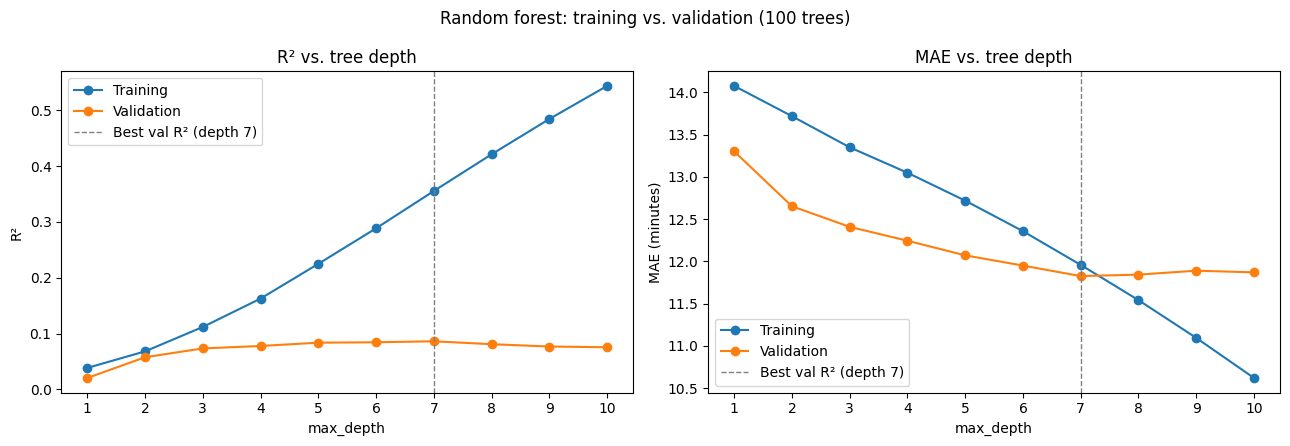

 depth  train_r2  val_r2  train_mae  val_mae
     1     0.039   0.021     14.077   13.303
     2     0.068   0.058     13.719   12.654
     3     0.112   0.074     13.351   12.409
     4     0.163   0.078     13.050   12.245
     5     0.225   0.084     12.720   12.072
     6     0.289   0.085     12.358   11.951
     7     0.355   0.086     11.959   11.827
     8     0.421   0.081     11.542   11.844
     9     0.484   0.077     11.095   11.891
    10     0.544   0.076     10.621   11.871


In [37]:
# Random forest diagnostic plots.

from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error


def horizontal_boxplot(ax, values, labels):
    try:
        ax.boxplot(values, orientation="horizontal", tick_labels=labels)
    except TypeError:
        ax.boxplot(values, vert=False, labels=labels)


# =============================================================================
# 1. Training vs. validation performance as max_depth increases
# =============================================================================
depths = list(range(1, 11))
rows = []
for d in depths:
    model = RandomForestRegressor(
        n_estimators=100, max_depth=d, random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    rows.append({
        "depth": d,
        "train_r2": r2_score(y_train, train_pred),
        "val_r2": r2_score(y_val, val_pred),
        "train_mae": mean_absolute_error(y_train, train_pred),
        "val_mae": mean_absolute_error(y_val, val_pred),
    })
depth_results = pd.DataFrame(rows)
best_depth = depth_results.loc[depth_results["val_r2"].idxmax(), "depth"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, label in [(axes[0], "r2", "R²"), (axes[1], "mae", "MAE (minutes)")]:
    ax.plot(depth_results["depth"], depth_results[f"train_{metric}"], "o-", label="Training")
    ax.plot(depth_results["depth"], depth_results[f"val_{metric}"], "o-", label="Validation")
    ax.axvline(best_depth, color="gray", linestyle="--", linewidth=1,
               label=f"Best val R² (depth {best_depth})")
    ax.set_xlabel("max_depth")
    ax.set_ylabel(label)
    ax.set_xticks(depths)
    ax.legend()
axes[0].set_title("R² vs. tree depth")
axes[1].set_title("MAE vs. tree depth")
plt.suptitle("Random forest: training vs. validation (100 trees)")
plt.tight_layout()
plt.show()
print(depth_results.round(3).to_string(index=False))


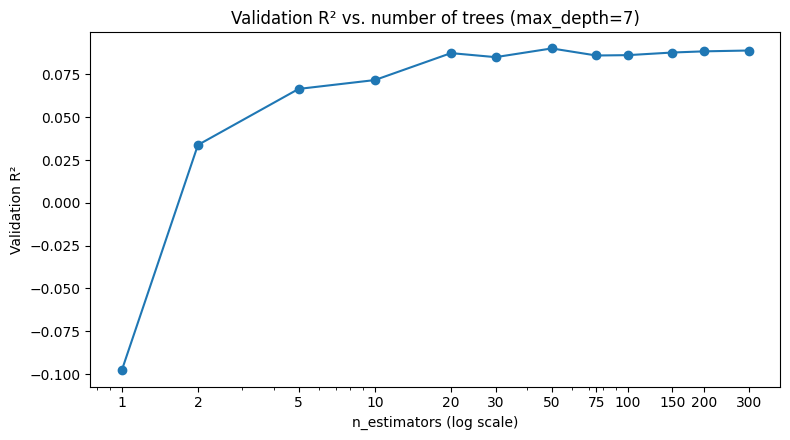

In [38]:
# =============================================================================
# 2. Validation performance as the number of trees increases
#    (fixed depth = best depth from above)
# =============================================================================
n_trees = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300]
val_r2_by_trees = []
for n in n_trees:
    model = RandomForestRegressor(
        n_estimators=n, max_depth=best_depth, random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    val_r2_by_trees.append(r2_score(y_val, model.predict(X_val)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n_trees, val_r2_by_trees, "o-")
ax.set_xscale("log")
ax.set_xticks(n_trees)
ax.set_xticklabels(n_trees)
ax.set_xlabel("n_estimators (log scale)")
ax.set_ylabel("Validation R²")
ax.set_title(f"Validation R² vs. number of trees (max_depth={best_depth})")
plt.tight_layout()
plt.show()



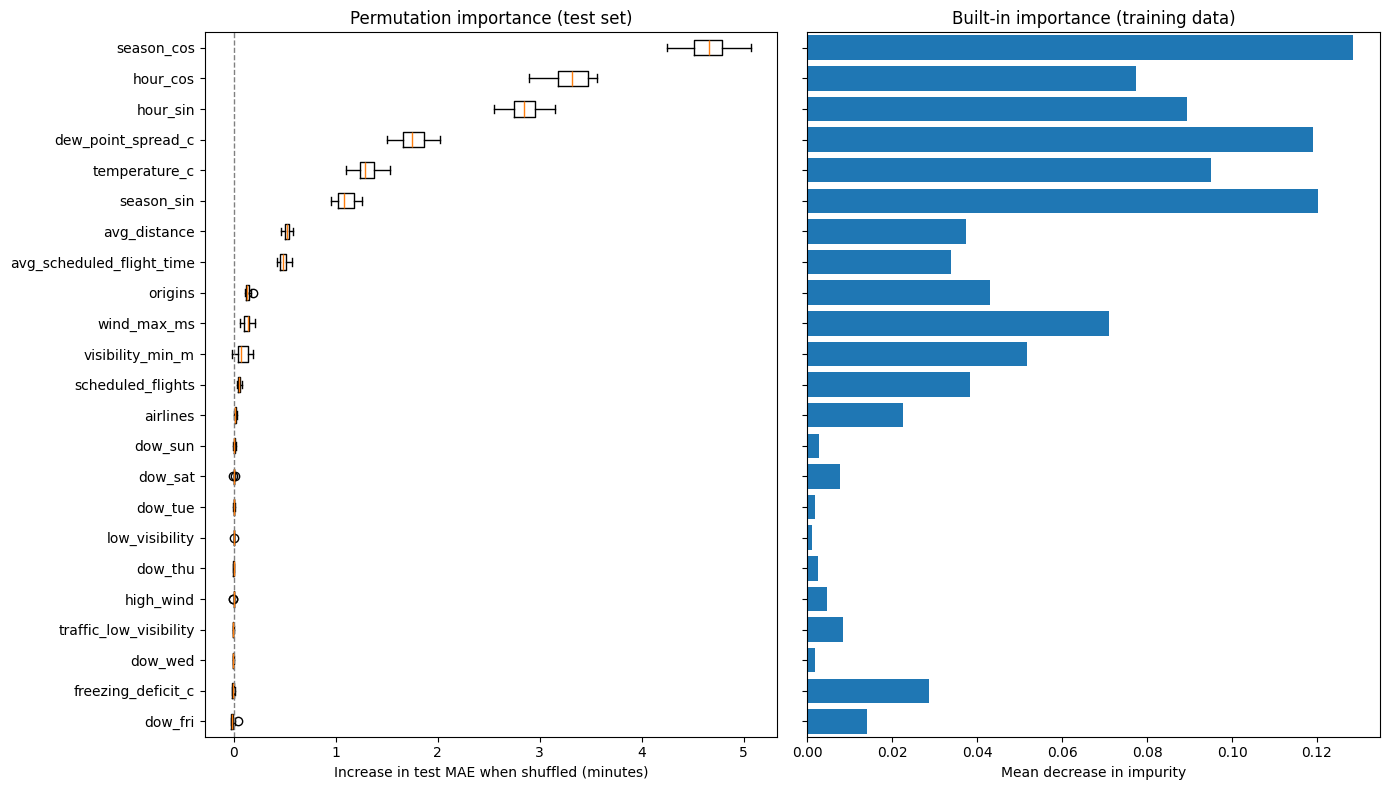

                           mean_increase_in_MAE    std  impurity_importance
season_cos                                4.650  0.208                0.128
hour_cos                                  3.312  0.187                0.077
hour_sin                                  2.848  0.149                0.089
dew_point_spread_c                        1.763  0.142                0.119
temperature_c                             1.312  0.110                0.095
season_sin                                1.102  0.091                0.120
avg_distance                              0.521  0.031                0.037
avg_scheduled_flight_time                 0.484  0.040                0.034
origins                                   0.137  0.020                0.043
wind_max_ms                               0.129  0.038                0.071
visibility_min_m                          0.086  0.061                0.052
scheduled_flights                         0.055  0.015                0.038
airlines    

In [39]:

# =============================================================================
# 3. Permutation importance vs. built-in (impurity) importance, on the test set
# =============================================================================
perm = permutation_importance(
    best_forest_model, X_test, y_test,
    scoring="neg_mean_absolute_error",  # importance = increase in MAE, in minutes
    n_repeats=20, random_state=42, n_jobs=-1,
)
perm_df = pd.DataFrame(perm.importances.T, columns=X_test.columns)
order = perm_df.mean().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
horizontal_boxplot(axes[0], perm_df[order].values, list(order))
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("Increase in test MAE when shuffled (minutes)")
axes[0].set_title("Permutation importance (test set)")

impurity = pd.Series(best_forest_model.feature_importances_, index=X_test.columns)
axes[1].barh(range(1, len(order) + 1), impurity[order].values)
axes[1].set_xlabel("Mean decrease in impurity")
axes[1].set_title("Built-in importance (training data)")
plt.tight_layout()
plt.show()

perm_summary = pd.DataFrame({
    "mean_increase_in_MAE": perm.importances_mean,
    "std": perm.importances_std,
    "impurity_importance": best_forest_model.feature_importances_,
}, index=X_test.columns).sort_values("mean_increase_in_MAE", ascending=False)
print(perm_summary.round(3))


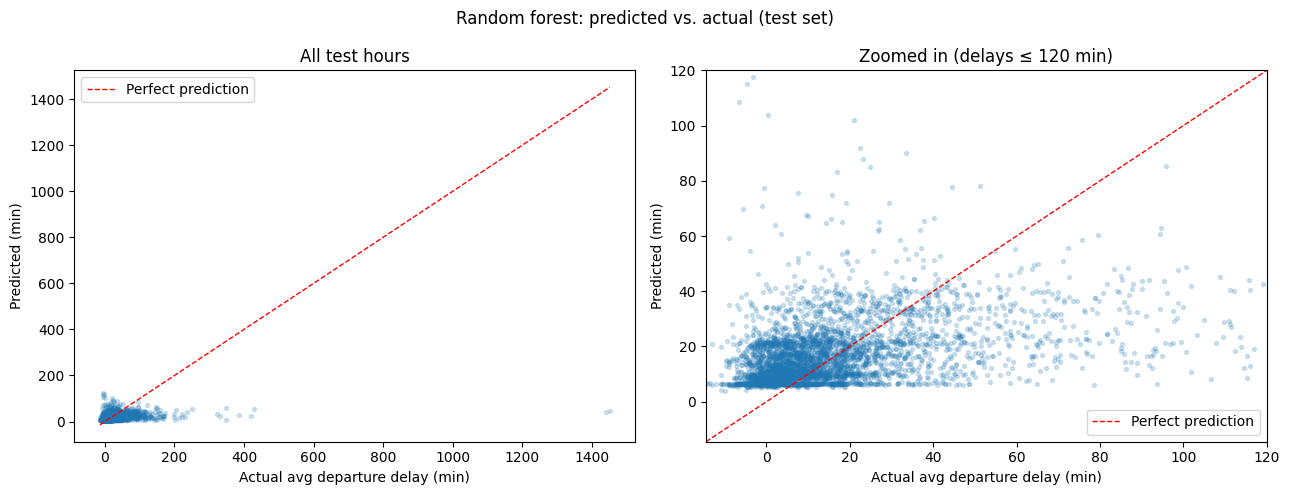

In [40]:


# =============================================================================
# 4. Predicted vs. actual on the test set
# =============================================================================
test_pred = best_forest_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, limit, title in [(axes[0], None, "All test hours"),
                         (axes[1], 120, "Zoomed in (delays ≤ 120 min)")]:
    ax.scatter(y_test, test_pred, alpha=0.2, s=8)
    top = limit if limit else max(y_test.max(), test_pred.max())
    low = min(y_test.min(), test_pred.min())
    ax.plot([low, top], [low, top], "r--", linewidth=1, label="Perfect prediction")
    if limit:
        ax.set_xlim(low, limit)
        ax.set_ylim(low, limit)
    ax.set_xlabel("Actual avg departure delay (min)")
    ax.set_ylabel("Predicted (min)")
    ax.set_title(title)
    ax.legend()
plt.suptitle("Random forest: predicted vs. actual (test set)")
plt.tight_layout()
plt.show()



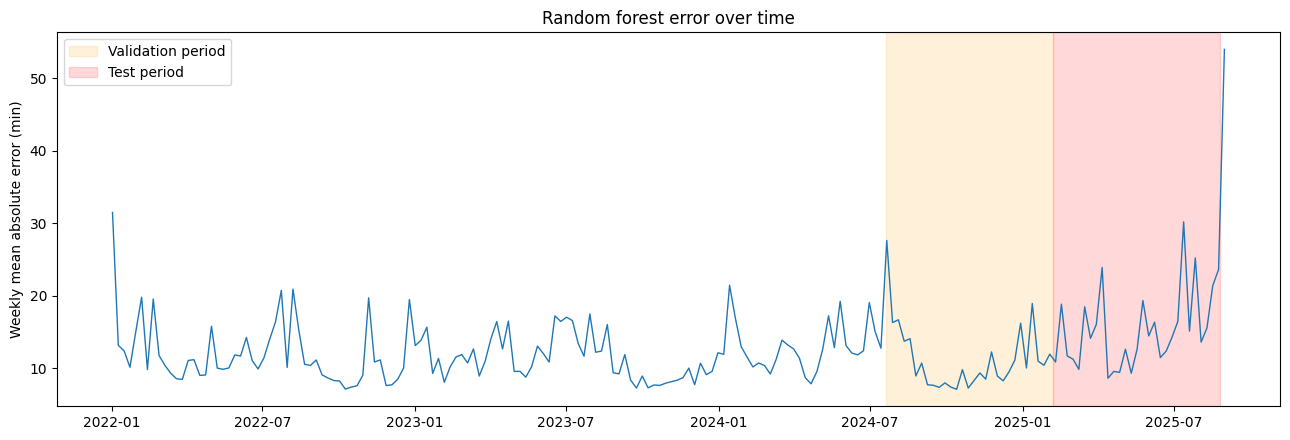

In [41]:


# =============================================================================
# 5. Errors over time (train / val / test) — shows how the test period differs
# =============================================================================
all_pred = best_forest_model.predict(data[X_test.columns])
errors = pd.DataFrame({
    "time": data["hour_local"].values,
    "abs_error": np.abs(data["avg_departure_delay"].values - all_pred),
}).set_index("time")
daily_mae = errors["abs_error"].resample("W").mean()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(daily_mae.index, daily_mae.values, linewidth=1)
ax.axvspan(data.loc[X_val.index, "hour_local"].min(),
           data.loc[X_val.index, "hour_local"].max(), alpha=0.15, color="orange",
           label="Validation period")
ax.axvspan(data.loc[X_test.index, "hour_local"].min(),
           data.loc[X_test.index, "hour_local"].max(), alpha=0.15, color="red",
           label="Test period")
ax.set_ylabel("Weekly mean absolute error (min)")
ax.set_title("Random forest error over time")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


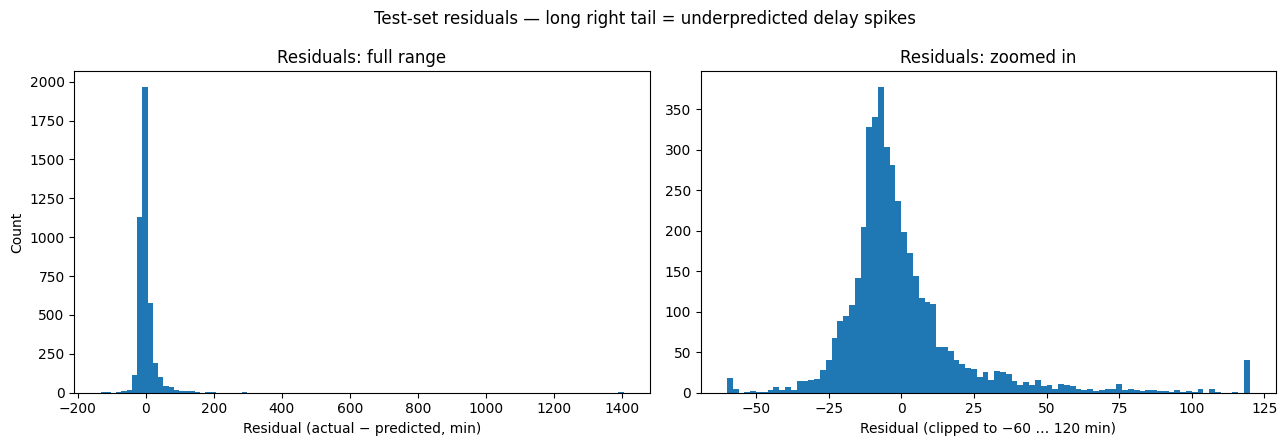

In [42]:
# =============================================================================
# 6. Residual distribution on the test set
# =============================================================================
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(residuals, bins=100)
axes[0].set_xlabel("Residual (actual − predicted, min)")
axes[0].set_ylabel("Count")
axes[0].set_title("Residuals: full range")
axes[1].hist(residuals.clip(-60, 120), bins=90)
axes[1].set_xlabel("Residual (clipped to −60 … 120 min)")
axes[1].set_title("Residuals: zoomed in")
plt.suptitle("Test-set residuals — long right tail = underpredicted delay spikes")
plt.tight_layout()
plt.show()


The random forest model with 31 estimators that have a max-depth of 7 performs better than the dummy model in all 3 metrics. I would note that the random forest model and the dummy model performs significantly worse than when the training sample was choosen randomly rather than the chronologically earlier portion, which reflects the importance of chronological data separation.

| Model                     | R²     | RMSE   | MAE    |
|---------------------------|-------:|-------:|-------:|
| Random forest             | 0.078  | 40.882 | 15.460 |
| Baseline (median)         | −0.059 | 43.828 | 16.368 |

While the r^2 is relatively low, the residual shows that the error is often less than 25 minutes.

After the optimal depth of 7, the trees become overfitted and increase in validation error, but increasing the number of trees after around 10 does not significantly increase R squared.

Rather than weather factors, it appears that the moment of season and time of day is the most significant features shown by the permutation importance test, followed by dew point and temperature. It would also appear that error also seems to concentrate on regions around January to March and then a summer spike around July to October. Belw are the results from training on just these spots:

| Test set                | Rows  | R²    | RMSE   | MAE    |
|-------------------------|------:|------:|-------:|-------:|
| Jan–Mar + Jul–Oct only  | 2,327 | 0.088 | 50.994 | 17.125 |
| Full test set           | 4,275 | 0.077 | 40.921 | 15.463 |

I then partitioned the value to those extrema months and the normal months to form a segmented model that predicts extrema months with extrema months model and normal months with normal months model, with the following results:

| Model         | Rows  | R²    | RMSE   | MAE    |
|---------------|------:|------:|-------:|-------:|
| Segmented     | 4,275 | 0.111 | 40.151 | 15.161 |
| Single forest | 4,275 | 0.072 | 41.027 | 15.465 |

This seems to have provided the best results.

Training rows (train + val): 21624, best depth: 6

Validation R² by depth (full validation set):
 depth    r2   rmse    mae
     2 0.055 23.392 12.512
     3 0.073 23.166 12.256
     4 0.074 23.151 12.201
     5 0.081 23.070 12.054
     6 0.083 23.042 11.917
     7 0.082 23.058 11.821
     8 0.082 23.052 11.736
     9 0.078 23.109 11.744
    10 0.073 23.175 11.783

Final test results:
               test_set  test_rows    r2   rmse    mae
Jan–Mar + Jul–Oct hours       2327 0.088 50.994 17.125
          full test set       4275 0.077 40.921 15.463


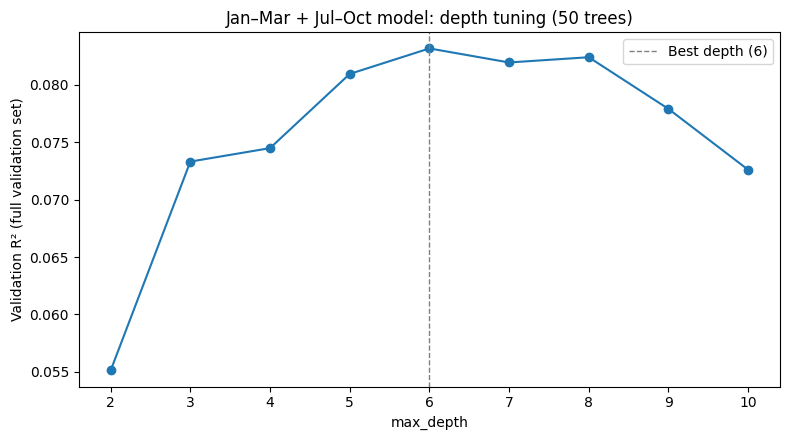

In [44]:
# One random forest trained on Jan–Mar and Jul–Oct together, tuned on the
# notebook's normal validation set.
# Assumes `data` (sorted by hour_local) and `core_features` exist from the notebook.
#
# Splits are the notebook's usual chronological 70 / 15 / 15:
#   train      = first 70% of hours  (Jan 2022 – Jul 20, 2024)
#   validation = next 15%            (Jul 20, 2024 – Feb 5, 2025), ALL months
#   test       = last 15%            (Feb 5 – Aug 25, 2025)
#
# Training set: 2/3 hours from Jan–Mar + Jul–Oct, 1/3 random hours from the other
# months (Apr–Jun, Nov–Dec), drawn only from the training split. Depth is tuned on
# the full validation set, then the model is refit on train + validation (same
# 2/3 + 1/3 recipe) and tested.

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

season_months = [1, 2, 3, 7, 8, 9, 10]
n_trees = 50
depths = range(2, 11)
target = "avg_departure_delay"

train_end = int(len(data) * 0.70)
val_end = int(len(data) * 0.85)
train_split = data.iloc[:train_end]
val_split = data.iloc[train_end:val_end]
test_split = data.iloc[val_end:]


def seasonal_training_set(pool, months, seed=42):
    """All in-season rows from `pool`, plus off-season rows making up 1/3 of the total."""
    in_season = pool[pool["hour_local"].dt.month.isin(months)]
    off_season = pool[~pool["hour_local"].dt.month.isin(months)]
    extra = off_season.sample(n=len(in_season) // 2, random_state=seed)
    return pd.concat([in_season, extra]).sort_values("hour_local")


def scores(model, df):
    pred = model.predict(df[core_features])
    y = df[target]
    return {
        "r2": r2_score(y, pred),
        "rmse": root_mean_squared_error(y, pred),
        "mae": mean_absolute_error(y, pred),
    }


# ---- Tune depth: fit on the training split, score on the whole validation set
train = seasonal_training_set(train_split, season_months)
tuning_results = []
for d in depths:
    model = RandomForestRegressor(n_estimators=n_trees, max_depth=d,
                                  random_state=42, n_jobs=-1)
    model.fit(train[core_features], train[target])
    tuning_results.append({"depth": d, **scores(model, val_split)})

tuning_df = pd.DataFrame(tuning_results)
best_depth = int(tuning_df.loc[tuning_df["r2"].idxmax(), "depth"])

# ---- Refit on train + validation with the best depth, then test
train_val = seasonal_training_set(pd.concat([train_split, val_split]), season_months)
seasonal_model = RandomForestRegressor(n_estimators=n_trees, max_depth=best_depth,
                                       random_state=42, n_jobs=-1)
seasonal_model.fit(train_val[core_features], train_val[target])

test_in_season = test_split[test_split["hour_local"].dt.month.isin(season_months)]
final_df = pd.DataFrame([
    {"test_set": "Jan–Mar + Jul–Oct hours", "test_rows": len(test_in_season),
     **scores(seasonal_model, test_in_season)},
    {"test_set": "full test set", "test_rows": len(test_split),
     **scores(seasonal_model, test_split)},
])

print(f"Training rows (train + val): {len(train_val)}, best depth: {best_depth}")
print("\nValidation R² by depth (full validation set):")
print(tuning_df.round(3).to_string(index=False))
print("\nFinal test results:")
print(final_df.round(3).to_string(index=False))

# ---- Plot: validation R² vs. depth
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tuning_df["depth"], tuning_df["r2"], "o-")
ax.axvline(best_depth, color="gray", linestyle="--", linewidth=1,
           label=f"Best depth ({best_depth})")
ax.set_xlabel("max_depth")
ax.set_ylabel("Validation R² (full validation set)")
ax.set_title(f"Jan–Mar + Jul–Oct model: depth tuning ({n_trees} trees)")
ax.legend()
plt.tight_layout()
plt.show()

In [45]:
# Hard-gated "mixture of experts": one random forest for Jan–Mar + Jul–Oct,
# another for Apr–Jun + Nov–Dec. Each hour is routed to the expert for its month.
# Assumes `data` (sorted by hour_local) and `core_features` exist from the notebook.
# Uses the notebook's chronological 70 / 15 / 15 split.

import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

experts = {
    "Jan–Mar + Jul–Oct": [1, 2, 3, 7, 8, 9, 10],
    "Apr–Jun + Nov–Dec": [4, 5, 6, 11, 12],
}
n_trees = 50
depths = range(2, 11)
target = "avg_departure_delay"

train_end = int(len(data) * 0.70)
val_end = int(len(data) * 0.85)
train_split = data.iloc[:train_end]
val_split = data.iloc[train_end:val_end]
train_val_split = data.iloc[:val_end]
test_split = data.iloc[val_end:]


def in_months(df, months):
    return df[df["hour_local"].dt.month.isin(months)]


def metrics(y, pred):
    return {"r2": r2_score(y, pred),
            "rmse": root_mean_squared_error(y, pred),
            "mae": mean_absolute_error(y, pred)}


def tune_depth(train_df, val_df):
    """Return the depth with the best validation R², plus the full tuning table."""
    rows = []
    for d in depths:
        m = RandomForestRegressor(n_estimators=n_trees, max_depth=d, random_state=42, n_jobs=-1)
        m.fit(train_df[core_features], train_df[target])
        rows.append({"depth": d, **metrics(val_df[target], m.predict(val_df[core_features]))})
    table = pd.DataFrame(rows)
    return int(table.loc[table["r2"].idxmax(), "depth"]), table


# ---- Train each expert on its own months only, tuned on its own validation months
expert_models = {}
for name, months in experts.items():
    best_depth, table = tune_depth(in_months(train_split, months), in_months(val_split, months))
    print(f"{name}: best depth {best_depth}")
    fit_df = in_months(train_val_split, months)
    expert_models[name] = RandomForestRegressor(
        n_estimators=n_trees, max_depth=best_depth, random_state=42, n_jobs=-1
    ).fit(fit_df[core_features], fit_df[target])


def moe_predict(df):
    """Route each row to the expert for its month."""
    pred = pd.Series(np.nan, index=df.index)
    for name, months in experts.items():
        mask = df["hour_local"].dt.month.isin(months)
        if mask.any():
            pred[mask] = expert_models[name].predict(df.loc[mask, core_features])
    return pred.values


# ---- Single full-year forest with the same tuning procedure, for comparison
single_depth, _ = tune_depth(train_split, val_split)
single_model = RandomForestRegressor(
    n_estimators=n_trees, max_depth=single_depth, random_state=42, n_jobs=-1
).fit(train_val_split[core_features], train_val_split[target])
print(f"Single model: best depth {single_depth}")

# ---- Compare on the test set: overall and by expert's months
rows = []
for subset_name, subset in [("Full test set", test_split)] + \
        [(name, in_months(test_split, m)) for name, m in experts.items()]:
    y = subset[target]
    rows.append({"test_subset": subset_name, "model": "Mixture of experts",
                 "rows": len(subset), **metrics(y, moe_predict(subset))})
    rows.append({"test_subset": subset_name, "model": "Single forest",
                 "rows": len(subset), **metrics(y, single_model.predict(subset[core_features]))})

comparison = pd.DataFrame(rows)
print()
print(comparison.round(3).to_string(index=False))

Jan–Mar + Jul–Oct: best depth 5
Apr–Jun + Nov–Dec: best depth 6
Single model: best depth 7

      test_subset              model  rows     r2   rmse    mae
    Full test set Mixture of experts  4275  0.111 40.151 15.161
    Full test set      Single forest  4275  0.072 41.027 15.465
Jan–Mar + Jul–Oct Mixture of experts  2327  0.099 50.690 16.861
Jan–Mar + Jul–Oct      Single forest  2327  0.076 51.318 17.296
Apr–Jun + Nov–Dec Mixture of experts  1948  0.143 21.643 13.130
Apr–Jun + Nov–Dec      Single forest  1948 -0.002 23.411 13.278
